# LL and RR reconstruction efficiency versus signed η

Run with the LPC kernel. Input: `etaEff_cont.coffea`. This notebook plots only LL and RR on one numerical η axis, without heatmaps or intermediate plotting.

The observable is generated electron-pair η (`events.genEE.eta`), not individual-electron η or absolute η. Actual bin edges come from the loaded histograms and are checked across samples and categories. The same sample selection and regular pT/vxy bins as the ΔR notebook are used.

Efficiencies use summed numerator counts divided by the common generated denominator. Vertical bars show unit-weight binomial efficiency uncertainty, and horizontal bars show bin widths. Lines guide the eye. Zero-denominator bins remain gaps.

Restart an overloaded kernel before running. The entire coffea output must initially fit in memory, although only three required histograms are retained afterward. The final save cell is optional and writes files on LPC.


In [1]:
from pathlib import Path
import gc
import re
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from hist.intervals import ratio_uncertainty

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/etaEff_cont.coffea'
cut = 'cut0'

samples = {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}

print('Input:', f_sig)
print('Samples:', samples)


Input: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/etaEff_cont.coffea
Samples: {10: {0.2: [100]}, 20: {0.2: [100]}, 30: {0.2: [100]}, 40: {0.2: [100]}, 50: {0.2: [100]}, 60: {0.1: [100], 0.2: [100]}, 70: {0.1: [100], 0.2: [100]}, 80: {0.1: [100], 0.2: [100]}, 90: {0.1: [100], 0.2: [100]}, 100: {0.2: [100]}}


In [2]:
# Keep only the three required histograms after loading the file.
print('Loading coffea output...', flush=True)
loaded_output = util.load(str(f_sig))
sig_histo = loaded_output[0]
category_names = ('LL', 'RR', 'LR')
# category_names = ('LL', 'RR')
histograms = {
    suffix: sig_histo[f'genvtx_pt_vxy_eta_{suffix}']
    for suffix in ('den',) + category_names
}
del sig_histo, loaded_output
gc.collect()
print('Loaded. Retained only the three required histograms.', flush=True)

eta_edges_from_file = np.asarray(histograms['den'].axes['eta_den'].edges).copy()
if not np.all(np.isfinite(eta_edges_from_file)) or not np.all(np.diff(eta_edges_from_file) > 0):
    raise ValueError('Invalid eta bin edges.')
print('Eta bins:', len(eta_edges_from_file) - 1)
print('Eta edges:', eta_edges_from_file)


Loading coffea output...
Loaded. Retained only the three required histograms.
Eta bins: 50
Eta edges: [-5.  -4.8 -4.6 -4.4 -4.2 -4.  -3.8 -3.6 -3.4 -3.2 -3.  -2.8 -2.6 -2.4
 -2.2 -2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4
  0.6  0.8  1.   1.2  1.4  1.6  1.8  2.   2.2  2.4  2.6  2.8  3.   3.2
  3.4  3.6  3.8  4.   4.2  4.4  4.6  4.8  5. ]


In [3]:
# Select signal points using the same filename convention as plotTools.signalPoint.
# No plotTools import or 2D plotting is needed.
available_samples = list(histograms['den'].axes['samp'])
parsed_samples = []
for name in available_samples:
    match = re.search(r'Mchi-(\d+p\d+)_dMchi-(\d+p\d+)_ctau-(\d+)', name)
    if match is None:
        continue
    mchi = float(match.group(1).replace('p', '.'))
    dmchi = float(match.group(2).replace('p', '.'))
    lifetime = float(match.group(3))
    mass1 = mchi - dmchi / 2
    parsed_samples.append((name, mass1, dmchi / mass1, lifetime))

selected_names = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            matches = [
                name for name, mass1, splitting, lifetime in parsed_samples
                if np.isclose(mass1, m1, rtol=1e-8, atol=1e-8)
                and np.isclose(splitting, delta, rtol=1e-8, atol=1e-8)
                and lifetime == ctau
            ]
            if len(matches) != 1:
                raise ValueError(f'Expected one sample for {(m1, delta, ctau)}, found {matches}')
            if matches[0] in selected_names:
                raise ValueError(f'Duplicate sample: {matches[0]}')
            selected_names.append(matches[0])
if not selected_names:
    raise ValueError('No signal points selected.')
print('Selected samples:')
for name in selected_names:
    print(' ', name)

# Sum the 3D count array over pT and vxy, keeping all η bins in one step.
counts_vs_eta = {}
reference_edges = None
for suffix, histogram in histograms.items():
    summed = np.zeros(len(eta_edges_from_file) - 1, dtype=float)
    for name in selected_names:
        selected = histogram[{'samp': name, 'cut': cut}]
        names = tuple(axis.name for axis in selected.axes)
        expected_names = (f'pt_{suffix}', f'vxy_{suffix}', f'eta_{suffix}')
        if names != expected_names:
            raise ValueError(f'Unexpected axis order for {suffix}: {names}')
        current_edges = tuple(np.asarray(axis.edges).copy() for axis in selected.axes)
        if reference_edges is None:
            reference_edges = current_edges
        else:
            for expected, actual in zip(reference_edges, current_edges):
                np.testing.assert_array_equal(expected, actual)
        np.testing.assert_allclose(current_edges[2], eta_edges_from_file, rtol=0, atol=1e-12)
        summed += selected.values(flow=False).sum(axis=(0, 1))
    counts_vs_eta[suffix] = summed

pt_edges, vxy_edges, eta_edges = reference_edges
print(f'Included pT: [{pt_edges[0]:g}, {pt_edges[-1]:g}) GeV')
print(f'Included vxy: [{vxy_edges[0]:g}, {vxy_edges[-1]:g}) cm')
print('Underflow and overflow excluded.')
# Release histogram objects now that only small 1D count arrays are needed.
del histograms, histogram, selected
gc.collect()


Selected samples:
  sig_2022_Mchi-11p0_dMchi-2p0_ctau-100
  sig_2022_Mchi-22p0_dMchi-4p0_ctau-100
  sig_2022_Mchi-33p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-44p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-55p0_dMchi-10p0_ctau-100
  sig_2022_Mchi-63p0_dMchi-6p0_ctau-100
  sig_2022_Mchi-66p0_dMchi-12p0_ctau-100
  sig_2022_Mchi-73p5_dMchi-7p0_ctau-100
  sig_2022_Mchi-77p0_dMchi-14p0_ctau-100
  sig_2022_Mchi-84p0_dMchi-8p0_ctau-100
  sig_2022_Mchi-88p0_dMchi-16p0_ctau-100
  sig_2022_Mchi-94p5_dMchi-9p0_ctau-100
  sig_2022_Mchi-99p0_dMchi-18p0_ctau-100
  sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
Included pT: [0, 100) GeV
Included vxy: [0, 20) cm
Underflow and overflow excluded.


0

In [4]:
denominator = counts_vs_eta['den']
if not np.all(np.isfinite(denominator)) or np.any(denominator < 0):
    raise ValueError('Invalid denominator counts.')
if not np.allclose(denominator, np.round(denominator)):
    raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
valid = denominator > 0
curves = {}
for category in category_names:
    numerator = counts_vs_eta[category]
    if not np.all(np.isfinite(numerator)) or np.any(numerator < 0) or np.any(numerator > denominator):
        raise ValueError(f'Invalid {category} numerator counts.')
    if not np.allclose(numerator, np.round(numerator)):
        raise ValueError('This uncertainty calculation assumes unit-weight event counts.')
    efficiency = np.divide(numerator, denominator,
                           out=np.full_like(numerator, np.nan), where=valid)
    uncertainty = np.full((2, len(denominator)), np.nan)
    if np.any(valid):
        uncertainty[:, valid] = ratio_uncertainty(numerator[valid], denominator[valid], 'efficiency')
    curves[category] = {'efficiency': efficiency, 'uncertainty': uncertainty}
    print(f'\n{category}: bin interval, numerator / denominator, efficiency')
    for i, (low, high) in enumerate(zip(eta_edges[:-1], eta_edges[1:])):
        if valid[i]:
            print(f'  [{low:g}, {high:g}): {numerator[i]:g} / {denominator[i]:g} '
                  f'= {100 * efficiency[i]:.3f}% '
                  f'(-{100 * uncertainty[0,i]:.3f}, +{100 * uncertainty[1,i]:.3f} percentage points)')
        else:
            print(f'  [{low:g}, {high:g}): denominator 0, omitted')

if np.any(sum(counts_vs_eta[c] for c in category_names) > denominator):
    raise ValueError('LL + RR + LR counts exceed the common denominator.')



LL: bin interval, numerator / denominator, efficiency
  [-5, -4.8): 5 / 7662 = 0.065% (-0.028, +0.044 percentage points)
  [-4.8, -4.6): 7 / 11290 = 0.062% (-0.023, +0.033 percentage points)
  [-4.6, -4.4): 15 / 16795 = 0.089% (-0.023, +0.030 percentage points)
  [-4.4, -4.2): 15 / 25193 = 0.060% (-0.015, +0.020 percentage points)
  [-4.2, -4): 18 / 36759 = 0.049% (-0.011, +0.014 percentage points)
  [-4, -3.8): 25 / 53329 = 0.047% (-0.009, +0.011 percentage points)
  [-3.8, -3.6): 32 / 75788 = 0.042% (-0.007, +0.009 percentage points)
  [-3.6, -3.4): 55 / 104544 = 0.053% (-0.007, +0.008 percentage points)
  [-3.4, -3.2): 63 / 138203 = 0.046% (-0.006, +0.006 percentage points)
  [-3.2, -3): 136 / 178364 = 0.076% (-0.007, +0.007 percentage points)
  [-3, -2.8): 274 / 220668 = 0.124% (-0.007, +0.008 percentage points)
  [-2.8, -2.6): 862 / 266576 = 0.323% (-0.011, +0.011 percentage points)
  [-2.6, -2.4): 1902 / 309311 = 0.615% (-0.014, +0.014 percentage points)
  [-2.4, -2.2): 3656 / 3

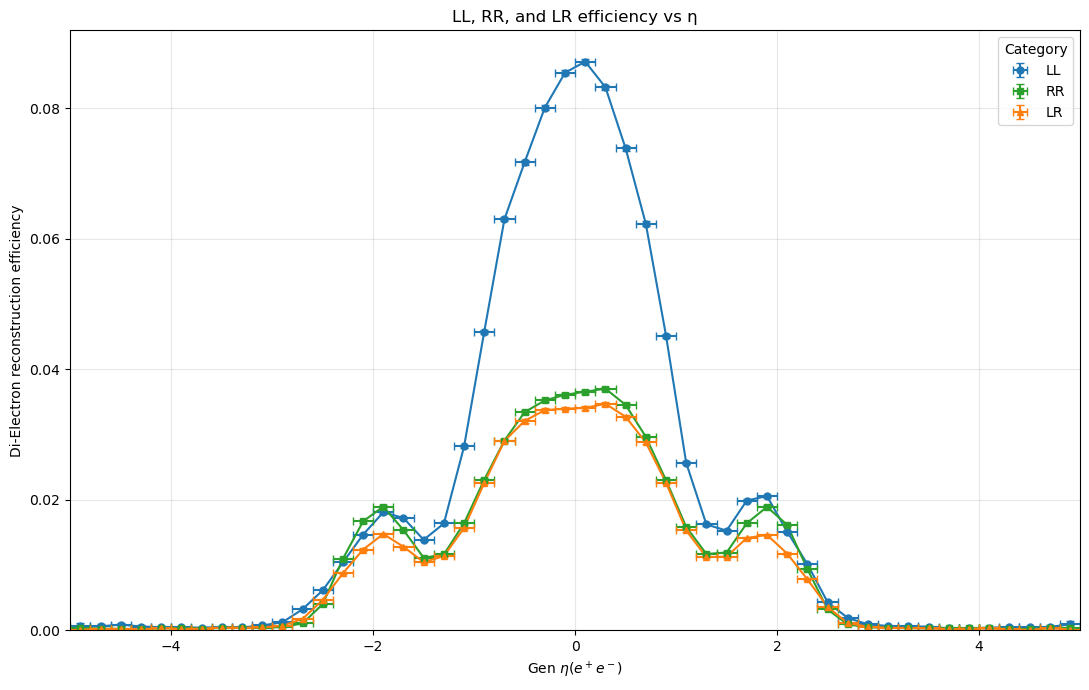

In [5]:
x = (eta_edges[:-1] + eta_edges[1:]) / 2
xerr = np.vstack((x - eta_edges[:-1], eta_edges[1:] - x))

colours = {
    'LL': 'tab:blue',
    'RR': 'tab:green',
    'LR': 'tab:orange',
}

markers = {
    'LL': 'o',
    'RR': 's',
    'LR': '^',
}



fig, ax = plt.subplots(figsize=(11, 7))

for category in category_names:
# for category in ('LL', 'RR'):
    efficiency = curves[category]['efficiency']
    uncertainty = curves[category]['uncertainty']
    finite = np.isfinite(efficiency)

    ax.plot(
        x, efficiency,
        color=colours[category],
        linewidth=1.5,
    )

    ax.errorbar(
        x[finite],
        efficiency[finite],
        xerr=xerr[:, finite],
        yerr=uncertainty[:, finite],
        fmt=markers[category],
        color=colours[category],
        markersize=5,
        capsize=3,
        label=category,
    )

ax.set_xlim(eta_edges[0], eta_edges[-1])
ax.set_ylim(bottom=0)
ax.set_xlabel(r'Gen $\eta(e^+e^-)$')
ax.set_ylabel('Di-Electron reconstruction efficiency')
ax.set_title('LL, RR, and LR efficiency vs η')
ax.grid(alpha=0.3)
ax.legend(title='Category')

fig.tight_layout()
plt.show()

## Optional: save the one figure
Only run the following cell if you want to create PNG and PDF files on LPC. It makes a new folder each time and saves the figure above without redrawing it.


In [6]:
from datetime import datetime
output_parent = LPC_REPO / 'python_analysis/plots/VertexRecEff_vs_eta_curve_only'
output_parent.mkdir(parents=True, exist_ok=True)
output_dir = output_parent / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
output_dir.mkdir(exist_ok=False)
for extension in ('png', 'pdf'):
    destination = output_dir / f'LL_RR_LR_efficiency_vs_eta.{extension}'
    # destination = output_dir / f'LL_RR_efficiency_vs_eta.{extension}'
    with destination.open('xb') as stream:
        fig.savefig(stream, format=extension, dpi=300, bbox_inches='tight', facecolor='white')
    print('Saved:', destination)


Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_eta_curve_only/20261015_135738_291577/LL_RR_LR_efficiency_vs_eta.png
Saved: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/plots/VertexRecEff_vs_eta_curve_only/20261015_135738_291577/LL_RR_LR_efficiency_vs_eta.pdf
